## Vibration-Based Motor Fault Diagnosis Using a 1-D ResNet
1. Environment Setup
Import the libraries required for model training, evaluation, visualization, and saving experimental results.

In [1]:
from google.colab import drive
from pathlib import Path
import sys
import subprocess
import copy
import time
import gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay)

DRIVE_ROOT = Path("/content/drive/MyDrive")

if not DRIVE_ROOT.is_dir():
    drive.mount("/content/drive")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Mounted at /content/drive
Using device: cuda


1.1. Project Configuration
Define the dataset location and the directories used to store model checkpoints and experimental results.

The original experiments use vibration windows of 1024 samples.

In [2]:
PROJECT_DIR = DRIVE_ROOT / "ISCF_Project"
WINDOW_SIZE = 1024
DATA_PATH = PROJECT_DIR / "data" / f"hustmotor_{WINDOW_SIZE}.npz"
RESULTS_DIR = PROJECT_DIR / "results" / "ResNet"
CHECKPOINT_DIR = PROJECT_DIR / "checkpoints" / "ResNet"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

print("Dataset:", DATA_PATH)
print("Results:", RESULTS_DIR)
print("Checkpoints:", CHECKPOINT_DIR)

Dataset: /content/drive/MyDrive/ISCF_Project/data/hustmotor_1024.npz
Results: /content/drive/MyDrive/ISCF_Project/results/ResNet
Checkpoints: /content/drive/MyDrive/ISCF_Project/checkpoints/ResNet


1.2. Data Preparation Utilities
Import the preprocessing function and shared utilities for reproducibility, vibration dataset preparation, and DataLoader creation.

These functions are reused across the different vibration-based models.

In [3]:
# Shared utilities
NOTEBOOKS_DIR = PROJECT_DIR / "notebooks"

if str(NOTEBOOKS_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOKS_DIR))

from data_utils import (
    set_seed,
    make_loader,
    create_task_datasets
)

# Preprocessing repository
REPO_DIR = Path("/content/ISCF_Project")

if not (REPO_DIR / "preprocess_hustmotor.py").is_file():
    if REPO_DIR.exists():
        raise RuntimeError(
            "Repository directory exists, but the preprocessing script is missing."
        )

    subprocess.run(
        [
            "git", "clone",
            "https://github.com/Genti24-bit/ISCF_Project.git",
            str(REPO_DIR)
        ],
        check=True
    )

if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

from preprocess_hustmotor import load_dg_task

print("Shared utilities imported successfully!")
print("Preprocessing loader imported successfully!")

Vibration batch: torch.Size([32, 1, 1024])
Labels batch: torch.Size([32])
Labels dtype: torch.int64
Shared utilities imported successfully!
Preprocessing loader imported successfully!


2. Vibration Dataset Preparation
Prepare the training, validation, and test datasets for Task 9 using the predefined domain-generalization splits.

The 5 Hz operating condition is held out for testing, while the remaining operating speeds are used for training and validation. Vibration signals are converted into PyTorch datasets and organized into batches.

In [4]:
TASK_ID = 9
TARGET_DOMAIN = 0
BATCH_SIZE = 256

train_dataset, val_dataset, test_dataset = create_task_datasets(
    DATA_PATH,
    target_domain=TARGET_DOMAIN,
    load_dg_task=load_dg_task
)

train_loader = make_loader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = make_loader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = make_loader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print(f"Task {TASK_ID}")
print("Training:", train_dataset.tensors[0].shape)
print("Validation:", val_dataset.tensors[0].shape)
print("Testing:", test_dataset.tensors[0].shape)

xb, yb = next(iter(train_loader))

print("\nVibration batch:", xb.shape)
print("Labels batch:", yb.shape)

Task 9
Training: torch.Size([14400, 1, 1024])
Validation: torch.Size([3600, 1, 1024])
Testing: torch.Size([1200, 1, 1024])

Vibration batch: torch.Size([256, 1, 1024])
Labels batch: torch.Size([256])


3. 1-D ResNet Architecture
Define a residual 1-D network with a convolutional stem, four residual blocks, and global average pooling. Each residual block combines a two-layer convolutional path with a skip connection; a 1×1 projection matches dimensions when needed. A fully connected layer produces six class logits. Softmax is not added because cross-entropy loss expects logits.

In [5]:
class ResidualBlock1D(nn.Module):
    """Two convolutional layers with an identity/projection shortcut."""

    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv1d(in_channels, out_channels, kernel_size=3,
                               stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm1d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv1d(out_channels, out_channels, kernel_size=3,
                               stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm1d(out_channels)
        self.shortcut = (
            nn.Identity()
            if in_channels == out_channels and stride == 1
            else nn.Sequential(
                nn.Conv1d(in_channels, out_channels, kernel_size=1,
                          stride=stride, bias=False),
                nn.BatchNorm1d(out_channels)
            )
        )

    def forward(self, x):
        residual = self.shortcut(x)
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.bn2(self.conv2(x))
        return self.relu(x + residual)


class VibrationResNet1D(nn.Module):
    """1-D residual network for 1024-point vibration inputs."""

    def __init__(self, n_classes=6):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=7, stride=2, padding=3, bias=False),
            nn.BatchNorm1d(16),
            nn.ReLU(inplace=True)
        )
        self.blocks = nn.Sequential(
            ResidualBlock1D(16, 16),
            ResidualBlock1D(16, 32, stride=2),
            ResidualBlock1D(32, 64, stride=2),
            ResidualBlock1D(64, 64)
        )
        self.pool = nn.AdaptiveAvgPool1d(1)
        self.classifier = nn.Linear(64, n_classes)

    def extract_features(self, x):
        x = self.stem(x)
        x = self.blocks(x)
        return self.pool(x).flatten(1)

    def forward(self, x):
        return self.classifier(self.extract_features(x))


model = VibrationResNet1D().to(device)
print(model)
print("\nTotal parameters:", sum(p.numel() for p in model.parameters()))


VibrationResNet1D(
  (stem): Sequential(
    (0): Conv1d(1, 16, kernel_size=(7,), stride=(2,), padding=(3,), bias=False)
    (1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
  )
  (blocks): Sequential(
    (0): ResidualBlock1D(
      (conv1): Conv1d(16, 16, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
      (bn1): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv1d(16, 16, kernel_size=(3,), stride=(1,), padding=(1,), bias=False)
      (bn2): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (shortcut): Identity()
    )
    (1): ResidualBlock1D(
      (conv1): Conv1d(16, 32, kernel_size=(3,), stride=(2,), padding=(1,), bias=False)
      (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv1d(32, 32, kernel_size

3.1. Architecture Verification
Verify that 1024-point vibration windows produce 64-dimensional pooled features and six class logits.

In [6]:
model.eval()

dummy_input = torch.randn(8, 1, WINDOW_SIZE,device=device)

with torch.no_grad():
    features = model.extract_features(dummy_input)
    outputs = model(dummy_input)

print("Input:", dummy_input.shape)
print("Features:", features.shape)
print("Output:", outputs.shape)

assert features.shape == (8, 64)
assert outputs.shape == (8, 6)

print("\nArchitecture verification passed!")

Input: torch.Size([8, 1, 1024])
Features: torch.Size([8, 64])
Output: torch.Size([8, 6])

Architecture verification passed!


4. Training Configuration
Configure the ResNet training procedure using the Adam optimizer, cross-entropy loss, and a decaying learning-rate schedule.

Each experiment runs for 50 epochs. Random seeds are controlled to support reproducibility and comparison across repeated experiments.

In [7]:
INITIAL_LR = 0.0005
EPOCHS = 50
SEED = 0

def learning_rate_schedule(epoch, total_epochs=EPOCHS):
    p = epoch / total_epochs
    return INITIAL_LR / ((1 + 10 * p) ** 0.75)

set_seed(SEED)

print("Initial learning rate:", learning_rate_schedule(0))
print("Final learning rate:", learning_rate_schedule(EPOCHS - 1))

Initial learning rate: 0.0005
Final learning rate: 8.392709437102133e-05


4.1. Model Evaluation
Define a reusable evaluation function to calculate classification loss and accuracy without updating the model parameters.

The function is used to evaluate validation performance during training and unseen-domain performance after checkpoint selection.

In [8]:
def evaluate(model, loader, criterion):

    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for inputs, labels in loader:

            inputs = inputs.to(device)
            labels = labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, correct / total

4.2. ResNet Training Procedure
Define the training procedure using the Adam optimizer and cross-entropy loss.

At each epoch, record training and validation performance. Select the model checkpoint with the highest source-domain validation accuracy for final evaluation.

In [9]:
def train_model(train_loader, val_loader, seed=0, epochs=50, verbose=True):

    set_seed(seed)

    model = VibrationResNet1D().to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=INITIAL_LR
    )

    best_val_acc = -1.0
    best_epoch = 0
    best_weights = None
    history = []

    for epoch in range(epochs):

        lr = learning_rate_schedule(epoch, epochs)

        for group in optimizer.param_groups:
            group["lr"] = lr

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for inputs, labels in train_loader:

            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        val_loss, val_acc = evaluate(
            model, val_loader, criterion
        )

        history.append({
            "epoch": epoch + 1,
            "learning_rate": lr,
            "train_loss": train_loss,
            "train_accuracy": train_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        if verbose:
            print(
                f"Epoch {epoch + 1:02d}/{epochs} | "
                f"Train Loss: {train_loss:.4f} | "
                f"Train Acc: {train_acc:.2%} | "
                f"Val Loss: {val_loss:.4f} | "
                f"Val Acc: {val_acc:.2%}"
            )

    model.load_state_dict(best_weights)

    return model, pd.DataFrame(history), best_epoch, best_val_acc

5. Single-Run Evaluation
Train the 1-D ResNet for Task 9 using random seed 0, with the 5 Hz operating condition held out as the unseen target domain.

The model is trained for 50 epochs. At each epoch, training and validation loss and accuracy are reported to monitor convergence and generalization performance.

The checkpoint achieving the highest source-domain validation accuracy is selected for final evaluation on the unseen target domain.

In [11]:
TASK_ID = 9
SEED = 0

checkpoint_path = CHECKPOINT_DIR / "resnet_task9_seed0.pt"
history_path = RESULTS_DIR / "resnet_task9_seed0_history.csv"

print("Training 1-D ResNet — Task 9, Seed 0...\n")

set_seed(SEED)

train_loader = make_loader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

model, history, best_epoch, best_val_acc = train_model(
    train_loader,
    val_loader,
    seed=SEED,
    epochs=EPOCHS,
    verbose=True
)

# Save the new checkpoint
torch.save({
    "model_state_dict": model.state_dict(),
    "task": TASK_ID,
    "seed": SEED,
    "best_epoch": best_epoch,
    "best_val_accuracy": best_val_acc
}, checkpoint_path)

# Save all 50 epochs
history.to_csv(history_path, index=False)

print("\n" + "=" * 75)
print("TASK 9 — SEED 0 — TRAINING SUMMARY")
print("=" * 75)

print(f"Total epochs: {EPOCHS}")
print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_acc:.2%}")

best_row = history.loc[
    history["epoch"] == best_epoch
].iloc[0]

print(f"Training accuracy at best epoch: {best_row['train_accuracy']:.2%}")
print(f"Training loss at best epoch: {best_row['train_loss']:.4f}")
print(f"Validation loss at best epoch: {best_row['val_loss']:.4f}")

Training 1-D ResNet — Task 9, Seed 0...

Epoch 01/50 | Train Loss: 0.9707 | Train Acc: 69.84% | Val Loss: 0.5759 | Val Acc: 82.44%
Epoch 02/50 | Train Loss: 0.3660 | Train Acc: 91.02% | Val Loss: 0.2527 | Val Acc: 94.36%
Epoch 03/50 | Train Loss: 0.1756 | Train Acc: 97.01% | Val Loss: 0.1317 | Val Acc: 97.86%
Epoch 04/50 | Train Loss: 0.0999 | Train Acc: 98.94% | Val Loss: 0.0767 | Val Acc: 99.39%
Epoch 05/50 | Train Loss: 0.0631 | Train Acc: 99.58% | Val Loss: 0.0509 | Val Acc: 99.72%
Epoch 06/50 | Train Loss: 0.0425 | Train Acc: 99.85% | Val Loss: 0.0327 | Val Acc: 99.86%
Epoch 07/50 | Train Loss: 0.0310 | Train Acc: 99.89% | Val Loss: 0.0269 | Val Acc: 99.89%
Epoch 08/50 | Train Loss: 0.0248 | Train Acc: 99.93% | Val Loss: 0.0219 | Val Acc: 100.00%
Epoch 09/50 | Train Loss: 0.0206 | Train Acc: 99.96% | Val Loss: 0.0178 | Val Acc: 100.00%
Epoch 10/50 | Train Loss: 0.0168 | Train Acc: 99.97% | Val Loss: 0.0156 | Val Acc: 100.00%
Epoch 11/50 | Train Loss: 0.0145 | Train Acc: 99.98% | V

### 5.1. Learning Curves

Visualize training and validation accuracy and loss across the 50 epochs for Task 9, seed 0.

The selected checkpoint epoch is highlighted to illustrate model convergence and identify potential overfitting.

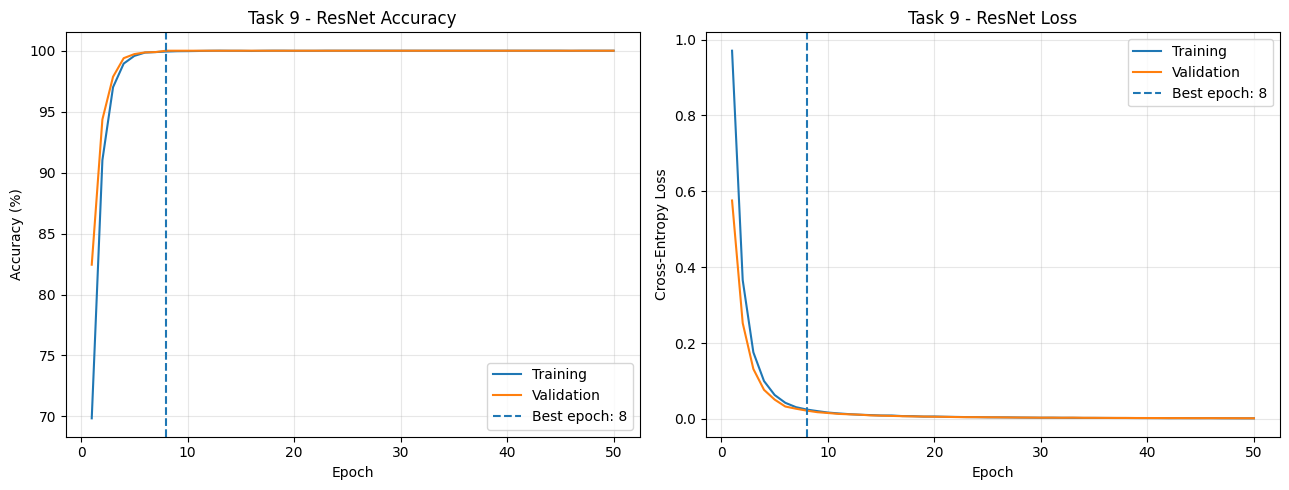

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    history["epoch"],
    history["train_accuracy"] * 100,
    label="Training"
)

axes[0].plot(
    history["epoch"],
    history["val_accuracy"] * 100,
    label="Validation"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

axes[0].set_title("Task 9 - ResNet Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history["epoch"],
    history["train_loss"],
    label="Training"
)

axes[1].plot(
    history["epoch"],
    history["val_loss"],
    label="Validation"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    label=f"Best epoch: {best_epoch}"
)

axes[1].set_title("Task 9 - ResNet Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 5.2. Unseen-Domain Evaluation

Evaluate the selected 1-D ResNet checkpoint on vibration samples from the unseen 5 Hz operating condition.

Report the final test accuracy and cross-entropy loss. The test set is used only for evaluation and does not influence model training or checkpoint selection.

In [13]:
criterion = nn.CrossEntropyLoss()

test_loss, test_acc = evaluate(
    model,
    test_loader,
    criterion
)

print("=" * 65)
print("TASK 9 — SEED 0 — TEST EVALUATION")
print("=" * 65)

print(f"Best epoch: {best_epoch}")
print(f"Best validation accuracy: {best_val_acc:.2%}")
print(f"Test accuracy: {test_acc:.2%}")
print(f"Test loss: {test_loss:.4f}")

TASK 9 — SEED 0 — TEST EVALUATION
Best epoch: 8
Best validation accuracy: 100.00%
Test accuracy: 57.75%
Test loss: 2.0991


### 5.3. Fault Classification Performance

Generate a classification report and confusion matrix for the selected Task 9 ResNet model.

Precision, recall, and F1-score are reported for each motor condition. The confusion matrix provides a detailed view of correctly classified samples and misclassifications.

              precision    recall  f1-score   support

           H       0.89      1.00      0.94       200
          BF       0.99      0.72      0.83       200
         BOW       0.00      0.00      0.00       200
      BROKEN       0.45      0.76      0.57       200
       MISAL       1.00      0.11      0.20       200
       UNBAL       0.37      0.88      0.52       200

    accuracy                           0.58      1200
   macro avg       0.62      0.58      0.51      1200
weighted avg       0.62      0.58      0.51      1200



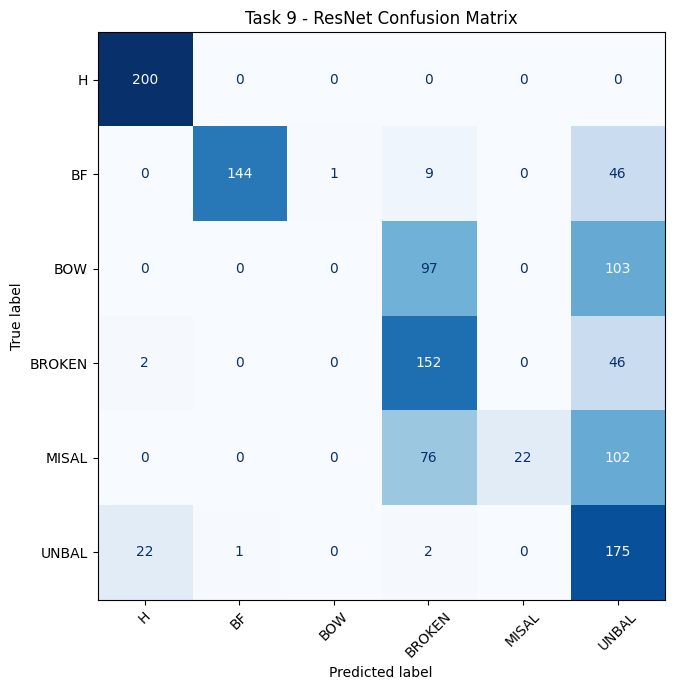

In [14]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for inputs, labels in test_loader:

        outputs = model(inputs.to(device))
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

with np.load(DATA_PATH, allow_pickle=False) as data:
    class_names = [str(c) for c in data["classes"]]

class_ids = list(range(len(class_names)))

print(
    classification_report(
        all_labels,
        all_predictions,
        labels=class_ids,
        target_names=class_names,
        zero_division=0
    )
)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=class_ids
)

fig, ax = plt.subplots(figsize=(9, 7))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Task 9 - ResNet Confusion Matrix")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 6. Full Experimental Evaluation

Evaluate the 1-D ResNet across four domain-generalization tasks using 10 random seeds per task.

Each experiment starts with a newly initialized model and is trained for 50 epochs. The checkpoint with the highest source-domain validation accuracy is selected for evaluation on the unseen operating speed.

Training, validation, and testing performance are recorded for each run to assess the model's accuracy, generalization, and stability.

In [15]:
TASKS = {
    9: 0,
    10: 1,
    11: 2,
    12: 3
}

SPEEDS = {
    9: 5,
    10: 10,
    11: 20,
    12: 30
}

SEEDS = range(10)

RUN_RESULTS_DIR = RESULTS_DIR / "full_experiments"
RUN_CHECKPOINT_DIR = CHECKPOINT_DIR / "full_experiments"

RUN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RUN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

print("Number of tasks:", len(TASKS))
print("Seeds per task:", len(SEEDS))
print("Total experiments:", len(TASKS) * len(SEEDS))

Number of tasks: 4
Seeds per task: 10
Total experiments: 40


### 6.1. ResNet Training Across Tasks and Seeds

Train the 1-D ResNet across Tasks 9–12 using 10 independent random seeds per task.

Each model is initialized and trained independently for 50 epochs. The checkpoint with the highest validation accuracy is selected for final testing.

For each experiment, report the best epoch, training and validation accuracy and loss, and unseen-domain test accuracy and loss. Save the model checkpoints, complete training histories, and detailed results for further analysis.

In [16]:
RUN_RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RUN_CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

all_results = []

for task_id, target_domain in TASKS.items():

    print("\n" + "=" * 90)
    print(
        f"TASK {task_id} | "
        f"Unseen operating speed: {SPEEDS[task_id]} Hz"
    )
    print("=" * 90)

    train_ds, val_ds, test_ds = create_task_datasets(
        DATA_PATH,
        target_domain=target_domain,
        load_dg_task=load_dg_task
    )

    val_dl = make_loader(
        val_ds,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    test_dl = make_loader(
        test_ds,
        batch_size=BATCH_SIZE,
        shuffle=False
    )

    task_results = []

    for seed in SEEDS:

        print(f"\n{'-' * 90}")
        print(f"TASK {task_id} — SEED {seed}")
        print(f"{'-' * 90}")

        set_seed(seed)

        train_dl = make_loader(
            train_ds,
            batch_size=BATCH_SIZE,
            shuffle=True
        )

        start_time = time.time()

        # A new ResNet is initialized inside train_model()
        trained_model, history_df, best_epoch, best_val_acc = train_model(
            train_dl,
            val_dl,
            seed=seed,
            epochs=EPOCHS,
            verbose=False
        )

        test_loss, test_acc = evaluate(
            trained_model,
            test_dl,
            nn.CrossEntropyLoss()
        )

        training_time = time.time() - start_time

        best_row = history_df.loc[
            history_df["epoch"] == best_epoch
        ].iloc[0]

        train_loss = float(best_row["train_loss"])
        train_acc = float(best_row["train_accuracy"])

        val_loss = float(best_row["val_loss"])
        val_acc = float(best_row["val_accuracy"])

        result = {
            "Task": task_id,
            "Speed (Hz)": SPEEDS[task_id],
            "Seed": seed,
            "Best Epoch": best_epoch,
            "Train Loss": train_loss,
            "Train Accuracy (%)": train_acc * 100,
            "Val Loss": val_loss,
            "Val Accuracy (%)": val_acc * 100,
            "Test Loss": test_loss,
            "Test Accuracy (%)": test_acc * 100,
            "Training Time (s)": training_time
        }

        task_results.append(result)
        all_results.append(result)

        print(
            f"Best Epoch: {best_epoch} | "
            f"Train Acc: {train_acc:.2%} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Acc: {val_acc:.2%} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Test Acc: {test_acc:.2%} | "
            f"Test Loss: {test_loss:.4f}"
        )

        # Save model checkpoint
        checkpoint_path = (
            RUN_CHECKPOINT_DIR /
            f"resnet_task{task_id}_seed{seed}.pt"
        )

        torch.save({
            "model_state_dict": trained_model.state_dict(),
            "task": task_id,
            "seed": seed,
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_acc,
            "test_accuracy": test_acc,
            "test_loss": test_loss
        }, checkpoint_path)

        # Save all 50 training epochs
        history_path = (
            RUN_RESULTS_DIR /
            f"resnet_task{task_id}_seed{seed}_history.csv"
        )

        history_df.to_csv(history_path, index=False)

        # Save individual experiment results
        result_path = (
            RUN_RESULTS_DIR /
            f"resnet_task{task_id}_seed{seed}_result.csv"
        )

        pd.DataFrame([result]).to_csv(
            result_path,
            index=False
        )

        # Save combined progress after every run
        pd.DataFrame(all_results).to_csv(
            RUN_RESULTS_DIR / "resnet_detailed_results.csv",
            index=False
        )

        del trained_model
        gc.collect()

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    # Display results for the current task
    task_df = pd.DataFrame(task_results)

    print("\n" + "=" * 90)
    print(f"TASK {task_id} — RESULTS FOR ALL 10 SEEDS")
    print("=" * 90)

    display(
        task_df.style.format({
            "Train Loss": "{:.4f}",
            "Train Accuracy (%)": "{:.2f}",
            "Val Loss": "{:.4f}",
            "Val Accuracy (%)": "{:.2f}",
            "Test Loss": "{:.4f}",
            "Test Accuracy (%)": "{:.2f}",
            "Training Time (s)": "{:.1f}"
        })
    )

    print(
        f"\nMean Test Accuracy: "
        f"{task_df['Test Accuracy (%)'].mean():.2f}%"
    )

    print(
        f"Standard Deviation: "
        f"{task_df['Test Accuracy (%)'].std(ddof=1):.2f}%"
    )

# Final results
detailed_results_df = pd.DataFrame(all_results)

print("\n" + "=" * 90)
print("ALL 40 RESNET EXPERIMENTS COMPLETED")
print("=" * 90)

print(f"Total runs: {len(detailed_results_df)}")

display(detailed_results_df)

print(
    "\nSaved results to:",
    RUN_RESULTS_DIR / "resnet_detailed_results.csv"
)


TASK 9 | Unseen operating speed: 5 Hz

------------------------------------------------------------------------------------------
TASK 9 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 8 | Train Acc: 99.93% | Train Loss: 0.0248 | Val Acc: 100.00% | Val Loss: 0.0219 | Test Acc: 57.75% | Test Loss: 2.0991

------------------------------------------------------------------------------------------
TASK 9 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 16 | Train Acc: 100.00% | Train Loss: 0.0081 | Val Acc: 100.00% | Val Loss: 0.0084 | Test Acc: 59.83% | Test Loss: 2.4068

------------------------------------------------------------------------------------------
TASK 9 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 9 | Train Acc: 99.96% | Train Loss: 0.0226 | Val Acc: 100.00% | Val Loss: 0.0206 | Tes

,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,9,5,0,8,0.0248,99.93,0.0219,100.00,2.0991,57.75,105.5
1,9,5,1,16,0.0081,100.00,0.0084,100.00,2.4068,59.83,98.7
2,9,5,2,9,0.0226,99.96,0.0206,100.00,2.0018,56.25,97.9
3,9,5,3,25,0.0062,99.99,0.0082,100.00,2.3653,54.83,98.1
4,9,5,4,39,0.0042,100.00,0.0108,99.92,3.0938,46.92,97.7
5,9,5,5,10,0.0154,99.99,0.0143,100.00,1.9759,60.00,97.7
6,9,5,6,33,0.0042,100.00,0.0108,99.75,3.4464,46.08,97.7
7,9,5,7,8,0.0244,99.92,0.0203,100.00,2.0301,53.42,97.8
8,9,5,8,40,0.0037,100.00,0.0080,99.92,2.8888,51.83,98.4
9,9,5,9,13,0.0129,99.99,0.0123,100.00,2.1852,56.33,97.6



Mean Test Accuracy: 54.33%
Standard Deviation: 4.85%

TASK 10 | Unseen operating speed: 10 Hz

------------------------------------------------------------------------------------------
TASK 10 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 47 | Train Acc: 100.00% | Train Loss: 0.0084 | Val Acc: 99.31% | Val Loss: 0.0298 | Test Acc: 83.33% | Test Loss: 0.8740

------------------------------------------------------------------------------------------
TASK 10 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 21 | Train Acc: 99.63% | Train Loss: 0.0276 | Val Acc: 98.94% | Val Loss: 0.0458 | Test Acc: 82.33% | Test Loss: 1.0801

------------------------------------------------------------------------------------------
TASK 10 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 47 | Train Acc: 99.99% | Tra

,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,10,10,0,47,0.0084,100.00,0.0298,99.31,0.8740,83.33,97.6
1,10,10,1,21,0.0276,99.63,0.0458,98.94,1.0801,82.33,97.6
2,10,10,2,47,0.0095,99.99,0.0317,99.17,1.2314,82.50,97.6
3,10,10,3,44,0.0105,99.97,0.0327,98.97,1.1359,82.83,97.7
4,10,10,4,50,0.0088,99.99,0.0362,98.89,1.2263,81.83,97.9
5,10,10,5,44,0.0076,99.99,0.0284,99.14,1.0671,82.75,97.8
6,10,10,6,28,0.0239,99.74,0.0581,98.42,1.0246,80.08,97.9
7,10,10,7,32,0.0159,99.81,0.0334,99.19,0.9293,82.50,97.8
8,10,10,8,48,0.0114,99.96,0.0404,98.72,1.3566,81.42,97.9
9,10,10,9,28,0.0200,99.73,0.0369,99.00,0.9746,82.00,97.9



Mean Test Accuracy: 82.16%
Standard Deviation: 0.91%

TASK 11 | Unseen operating speed: 20 Hz

------------------------------------------------------------------------------------------
TASK 11 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 40 | Train Acc: 99.97% | Train Loss: 0.0109 | Val Acc: 99.31% | Val Loss: 0.0316 | Test Acc: 83.33% | Test Loss: 0.5361

------------------------------------------------------------------------------------------
TASK 11 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 33 | Train Acc: 99.99% | Train Loss: 0.0123 | Val Acc: 99.03% | Val Loss: 0.0366 | Test Acc: 79.67% | Test Loss: 0.7915

------------------------------------------------------------------------------------------
TASK 11 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 26 | Train Acc: 99.86% | Trai

...


Mean Test Accuracy: 81.85%
Standard Deviation: 1.18%

TASK 12 | Unseen operating speed: 30 Hz

------------------------------------------------------------------------------------------
TASK 12 — SEED 0
------------------------------------------------------------------------------------------
Best Epoch: 48 | Train Acc: 99.99% | Train Loss: 0.0074 | Val Acc: 99.47% | Val Loss: 0.0261 | Test Acc: 83.67% | Test Loss: 0.7052

------------------------------------------------------------------------------------------
TASK 12 — SEED 1
------------------------------------------------------------------------------------------
Best Epoch: 47 | Train Acc: 100.00% | Train Loss: 0.0066 | Val Acc: 99.28% | Val Loss: 0.0269 | Test Acc: 82.92% | Test Loss: 0.5675

------------------------------------------------------------------------------------------
TASK 12 — SEED 2
------------------------------------------------------------------------------------------
Best Epoch: 29 | Train Acc: 99.85% | Tra

,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,12,30,0,48,0.0074,99.99,0.0261,99.47,0.7052,83.67,97.4
1,12,30,1,47,0.0066,100.00,0.0269,99.28,0.5675,82.92,98.1
2,12,30,2,29,0.0171,99.85,0.0413,98.89,0.6505,83.00,98.3
3,12,30,3,48,0.0072,99.99,0.0311,99.19,0.7062,82.75,98.0
4,12,30,4,50,0.0089,100.00,0.0341,99.17,0.7424,83.33,98.2
5,12,30,5,46,0.0061,100.00,0.0262,99.33,0.7288,80.25,98.6
6,12,30,6,50,0.0083,99.99,0.0552,98.19,0.8046,83.25,97.9
7,12,30,7,49,0.0069,99.97,0.0253,99.31,0.7249,82.17,97.9
8,12,30,8,46,0.0135,99.94,0.0405,98.89,0.6962,83.08,98.1
9,12,30,9,37,0.0118,99.95,0.0305,99.19,0.7191,83.00,97.9



Mean Test Accuracy: 82.74%
Standard Deviation: 0.96%

ALL 40 RESNET EXPERIMENTS COMPLETED
Total runs: 40


,Task,Speed (Hz),Seed,Best Epoch,Train Loss,Train Accuracy (%),Val Loss,Val Accuracy (%),Test Loss,Test Accuracy (%),Training Time (s)
0,9,5,0,8,0.024798,99.930556,0.021943,100.000000,2.099101,57.750000,105.458892
1,9,5,1,16,0.008076,100.000000,0.008374,100.000000,2.406752,59.833333,98.721016
2,9,5,2,9,0.022589,99.958333,0.020638,100.000000,2.001833,56.250000,97.914037
3,9,5,3,25,0.006220,99.993056,0.008201,100.000000,2.365290,54.833333,98.112376
4,9,5,4,39,0.004177,100.000000,0.010808,99.916667,3.093795,46.916667,97.742125
5,9,5,5,10,0.015367,99.993056,0.014250,100.000000,1.975927,60.000000,97.716837
6,9,5,6,33,0.004221,100.000000,0.010817,99.750000,3.446443,46.083333,97.674006
7,9,5,7,8,0.024369,99.916667,0.020284,100.000000,2.030095,53.416667,97.845851
8,9,5,8,40,0.003683,100.000000,0.008050,99.916667,2.888836,51.833333,98.424939
9,9,5,9,13,0.012907,99.986111,0.012283,100.000000,2.185223,56.333333,97.596581



Saved results to: /content/drive/MyDrive/ISCF_Project/results/ResNet/full_experiments/resnet_detailed_results.csv


### 6.2. Experimental Results Summary

Aggregate the results of the 40 ResNet experiments.

For each task, calculate the mean and standard deviation of test accuracy across 10 seeds, the mean test loss, and the average best epoch.

Verify that all task-seed combinations are represented before reporting the final results.

In [18]:
results_path = RUN_RESULTS_DIR / "resnet_detailed_results.csv"

if results_path.exists():
    results_df = pd.read_csv(results_path)
else:
    raise FileNotFoundError(
        "No experiment results found. Run Section 6.2 first."
    )

required_columns = {
    "Task",
    "Speed (Hz)",
    "Seed",
    "Best Epoch",
    "Test Loss",
    "Test Accuracy (%)"
}

assert required_columns.issubset(results_df.columns), (
    f"Missing columns: {required_columns - set(results_df.columns)}"
)

expected_runs = {
    (task_id, seed)
    for task_id in TASKS
    for seed in SEEDS
}

actual_runs = {
    (int(row["Task"]), int(row["Seed"]))
    for _, row in results_df.iterrows()
}

assert len(results_df) == 40, "Expected 40 results."

assert actual_runs == expected_runs, (
    "Missing or unexpected task-seed combinations."
)

summary_df = (
    results_df
    .groupby(["Task", "Speed (Hz)"])
    .agg(
        Mean_Test_Accuracy=("Test Accuracy (%)", "mean"),
        Std_Test_Accuracy=("Test Accuracy (%)", "std"),
        Mean_Test_Loss=("Test Loss", "mean"),
        Mean_Best_Epoch=("Best Epoch", "mean"),
        Number_of_Seeds=("Seed", "count")
    )
    .reset_index()
)

display(
    summary_df.style.format({
        "Mean_Test_Accuracy": "{:.2f}",
        "Std_Test_Accuracy": "{:.2f}",
        "Mean_Test_Loss": "{:.4f}",
        "Mean_Best_Epoch": "{:.1f}"
    })
)

overall_accuracy = summary_df["Mean_Test_Accuracy"].mean()

print(
    f"\nOverall Mean Test Accuracy: "
    f"{overall_accuracy:.2f}%"
)

summary_df.to_csv(
    RUN_RESULTS_DIR / "resnet_summary.csv",
    index=False
)

print("\nSummary saved successfully!")

,Task,Speed (Hz),Mean_Test_Accuracy,Std_Test_Accuracy,Mean_Test_Loss,Mean_Best_Epoch,Number_of_Seeds
0,9,5,54.33,4.85,2.4493,20.1,10
1,10,10,82.16,0.91,1.0900,38.9,10
2,11,20,81.85,1.18,0.6652,40.1,10
3,12,30,82.74,0.96,0.7045,45.0,10



Overall Mean Test Accuracy: 75.27%

Summary saved successfully!


### 6.3. Performance Across Unseen Operating Speeds

Visualize the mean test accuracy of the 1-D ResNet across the four unseen operating speeds.

Each bar represents the average accuracy across 10 independent runs, while the error bars indicate the standard deviation.

This visualization highlights differences in generalization performance and stability between the domain-generalization tasks.

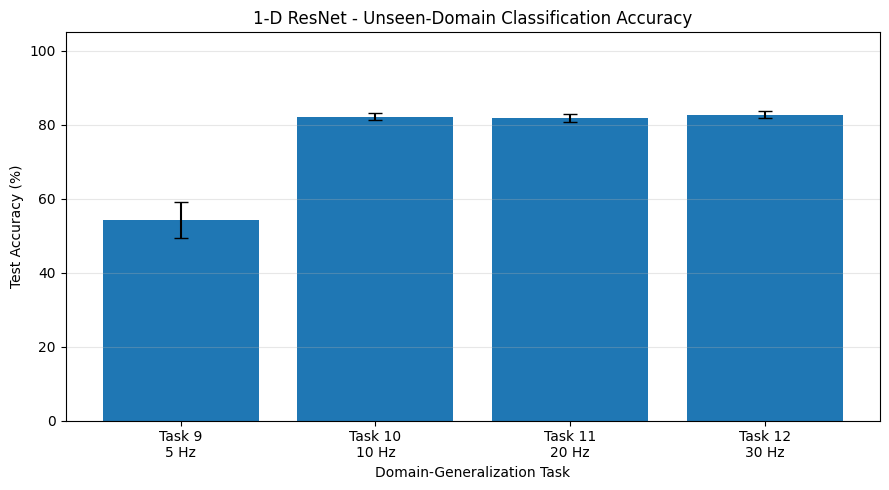

In [19]:
task_labels = [
    f"Task {int(row['Task'])}\n{int(row['Speed (Hz)'])} Hz"
    for _, row in summary_df.iterrows()
]

plt.figure(figsize=(9, 5))

plt.bar(
    task_labels,
    summary_df["Mean_Test_Accuracy"],
    yerr=summary_df["Std_Test_Accuracy"],
    capsize=5
)

plt.title(
    "1-D ResNet - Unseen-Domain Classification Accuracy"
)

plt.xlabel("Domain-Generalization Task")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()